# In-Context Learning and Instruction Fine-Tuning

| | **In-Context Learning (ICL)** | **Instruction Fine-Tuning (IFT)** |
|---|---|---|
| What is it? | The model learns a task from examples **in the prompt** | The model is **trained** on (instruction, response) pairs |
| Do weights change? | No | Yes |


## 0. Setup

In [ ]:
!pip install -q transformers datasets accelerate

In [ ]:
import random, gc, warnings
from html import escape
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display, HTML
from datasets import load_dataset
from transformers import (AutoTokenizer, AutoModelForCausalLM, DataCollatorForSeq2Seq,
                          Trainer, TrainingArguments)

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", None)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)


def set_seed(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)


def clear_gpu():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def load(name, **kwargs):
    tok = AutoTokenizer.from_pretrained(name)
    model = AutoModelForCausalLM.from_pretrained(name, **kwargs).to(device).eval()
    return tok, model


@torch.no_grad()
def generate(model, tok, prompt, max_new_tokens=40, first_line=False, **kwargs):
    """Greedy generation. Returns (text, stopped_on_its_own)."""
    enc = tok(prompt, return_tensors="pt").to(device)
    out = model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False,
                         pad_token_id=tok.eos_token_id, **kwargs)
    new = out[0, enc["input_ids"].shape[1]:]
    text = tok.decode(new, skip_special_tokens=True)
    if first_line:
        text = text.strip("\n ").split("\n")[0]
    return text.strip(), len(new) < max_new_tokens


@torch.no_grad()
def next_token_probs(model, tok, prompt, top=8):
    ids = tok(prompt, return_tensors="pt").input_ids.to(device)
    probs = torch.softmax(model(ids).logits[0, -1].float(), dim=-1)
    p, i = probs.topk(top)
    return [(repr(tok.decode([t])), v) for t, v in zip(i.tolist(), p.tolist())]


@torch.no_grad()
def word_logprob(model, tok, prompt, word):
    """log P(word | prompt), summed over all of the word's tokens."""
    p_ids = tok(prompt, return_tensors="pt").input_ids.to(device)
    w_ids = tok(word, add_special_tokens=False, return_tensors="pt").input_ids.to(device)
    ids = torch.cat([p_ids, w_ids], dim=1)
    logprobs = torch.log_softmax(model(ids).logits[0, :-1].float(), dim=-1)
    tgt = ids[0, 1:]
    return logprobs.gather(1, tgt.unsqueeze(1)).squeeze(1)[-w_ids.shape[1]:].sum().item()

Device: cuda


---
# Part 1: In-Context Learning

We use two **base** models (trained only to predict the next word, never instruction-tuned):
- **GPT-2** (124M parameters, 2019)
- **Qwen2.5-0.5B** (about 500M parameters, 2024)

In [ ]:
tok_g, model_g = load("openai-community/gpt2", attn_implementation="eager")   # eager -> lets us look at attention later
tok_q, model_q = load("Qwen/Qwen2.5-0.5B")
print("Models loaded.")

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

... (9 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

Models loaded.


## 1.1 A language model is just a next-token predictor
Before anything else: given some text, a language model outputs a probability for every possible next token. Everything in this notebook, prompting and fine-tuning alike, is built on this one ability.

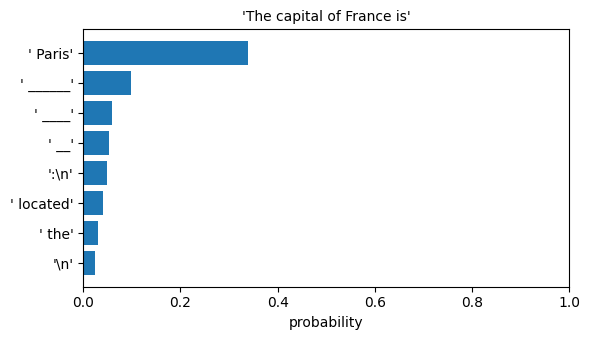

In [ ]:
def plot_next_tokens(model, tok, prompt, ax=None, title=None, top=8):
    pairs = next_token_probs(model, tok, prompt, top)[::-1]
    ax = ax or plt.subplots(figsize=(6, 3.5))[1]
    ax.barh([t for t, _ in pairs], [p for _, p in pairs], color="tab:blue")
    ax.set_xlim(0, 1); ax.set_xlabel("probability")
    ax.set_title(title or repr(prompt[-60:]), fontsize=10)

plot_next_tokens(model_q, tok_q, "The capital of France is")
plt.tight_layout(); plt.show()

> 💡 **Point out:** the model doesn't "answer a question". It assigns probabilities to continuations. In-context learning works by writing a prompt whose most likely continuation is the answer we want.

## 1.2 Zero-shot vs few-shot: the examples define the task
Each zero-shot prompt below is **ambiguous**. Does `hot →` ask for an antonym, a synonym, a translation? The few-shot prompts add three examples and nothing else: no instructions, no training.

In [ ]:
TASKS = {
    "Antonyms": "big → small\nfast → slow\nhappy → sad\n",
    "Country → capital": "France → Paris\nItaly → Rome\nEgypt → Cairo\n",
    "English → French": "dog → chien\nhouse → maison\nwater → eau\n",
    "Date → ISO format": "July 4, 1999 → 1999-07-04\nDecember 25, 2010 → 2010-12-25\nJanuary 17, 2003 → 2003-01-17\n",
    "Word → plural": "child → children\nmouse → mice\nbox → boxes\n",
}
QUERIES = {
    "Antonyms": "hot →",
    "Country → capital": "Japan →",
    "English → French": "cheese →",
    "Date → ISO format": "March 5, 2021 →",
    "Word → plural": "goose →",
}

rows = []
for task, examples in TASKS.items():
    q = QUERIES[task]
    zero, _ = generate(model_q, tok_q, q, max_new_tokens=10, first_line=True)
    few, _ = generate(model_q, tok_q, examples + q, max_new_tokens=10, first_line=True)
    rows.append({"task": task, "query": q, "zero-shot output": zero, "3-shot output": few})
display(pd.DataFrame(rows))

,task,query,zero-shot output,3-shot output
0,Antonyms,hot →,1. 1. 1.,cold
1,Country → capital,Japan →,Japan,Tokyo
2,English → French,cheese →,cheese,cheddar
3,Date → ISO format,"March 5, 2021 →",10:00 AM,2021-03-0
4,Word → plural,goose →,goose,goose


**Try it live:** invent a task in front of the class and see whether the model picks it up.

In [ ]:
my_examples = "cat → tac\ndog → god\nsun → nus\n"     # e.g. reversing a word; change this freely
my_query = "pin →"
for name, prompt in [("zero-shot", my_query), ("few-shot", my_examples + my_query)]:
    print(f"{name:9s}:", generate(model_q, tok_q, prompt, max_new_tokens=10, first_line=True)[0])

zero-shot: 100000000
few-shot : pin


> 💡 **Point out:** the same model, with the same weights, performs five different tasks. Only the prompt changed. The examples tell the model *which* task and *which output format*.

## 1.3 Learning a brand-new label from context
To show the model really uses the examples, we invent label words it has never seen with this meaning: **glorp** = positive, **blick** = negative. With zero examples the model cannot know what these words mean, so any success must come from the prompt.

We watch the probability of the correct label as we add examples.

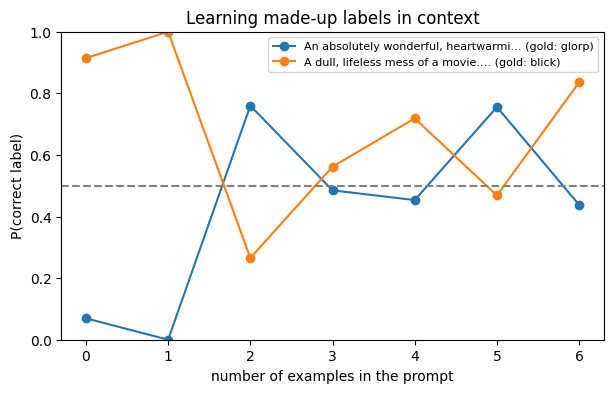

The full 6-shot prompt looks like this:

Review: Boring, predictable and far too long.
Label: blick

Review: I loved every minute of it.
Label: glorp

Review: The acting was wooden and the plot made no sense.
Label: blick

Review: A funny, warm film with a great cast.
Label: glorp

Review: I walked out halfway through.
Label: blick

Review: Beautifully shot and genuinely moving.
Label: glorp

Review: An absolutely wonderful, heartwarming story.
Label:


In [ ]:
DEMOS = [
    ("Boring, predictable and far too long.", "blick"),
    ("I loved every minute of it.", "glorp"),
    ("The acting was wooden and the plot made no sense.", "blick"),
    ("A funny, warm film with a great cast.", "glorp"),
    ("I walked out halfway through.", "blick"),
    ("Beautifully shot and genuinely moving.", "glorp"),
]
TESTS = [("An absolutely wonderful, heartwarming story.", "glorp"),
         ("A dull, lifeless mess of a movie.", "blick")]


def made_up_prompt(k, review):
    shots = "".join(f"Review: {r}\nLabel: {l}\n\n" for r, l in DEMOS[:k])
    return shots + f"Review: {review}\nLabel:"


K_RANGE = range(0, len(DEMOS) + 1)
fig, ax = plt.subplots(figsize=(7, 4))
for review, gold in TESTS:
    probs = []
    for k in K_RANGE:
        lp = {w: word_logprob(model_q, tok_q, made_up_prompt(k, review), " " + w) for w in ["glorp", "blick"]}
        z = np.logaddexp(lp["glorp"], lp["blick"])
        probs.append(np.exp(lp[gold] - z))       # P(correct | it's one of the two labels)
    ax.plot(list(K_RANGE), probs, marker="o", label=f"{review[:35]}… (gold: {gold})")
ax.axhline(0.5, ls="--", c="grey")
ax.set_xlabel("number of examples in the prompt"); ax.set_ylabel("P(correct label)")
ax.set_ylim(0, 1); ax.set_title("Learning made-up labels in context"); ax.legend(fontsize=8)
plt.show()

print("The full 6-shot prompt looks like this:\n")
print(made_up_prompt(6, TESTS[0][0]))

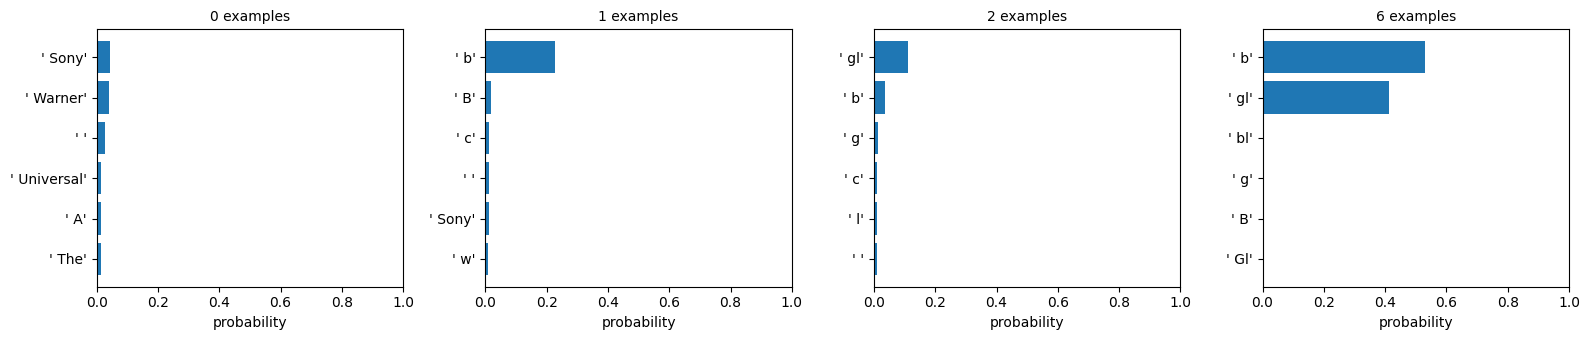

In [ ]:
# The model's top next-token guesses as examples are added (positive test review)
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, k in zip(axes, [0, 1, 2, 6]):
    plot_next_tokens(model_q, tok_q, made_up_prompt(k, TESTS[0][0]), ax=ax, title=f"{k} examples", top=6)
plt.tight_layout(); plt.show()

> 💡 **Point out:**
> - At k = 0 the model has no idea what "glorp" means, so it is close to a coin toss (or worse).
> - With only one example (a *blick* one) the model may simply copy the only label it has seen. That's a common failure: copying rather than understanding.
> - With more examples the model infers the **mapping** between review sentiment and the invented word.

### 1.4 Proof that nothing was "learned" permanently
In-context learning does not change the model. We take a fingerprint of all the weights, run a few-shot prompt, and check the fingerprint again. Then we remove the examples: the "skill" disappears instantly.

In [ ]:
def fingerprint(model):
    return sum(p.detach().double().sum().item() for p in model.parameters())

before = fingerprint(model_q)
_ = generate(model_q, tok_q, TASKS["Antonyms"] + "hot →", max_new_tokens=5)
after = fingerprint(model_q)
print(f"Weight fingerprint before: {before:.6f}")
print(f"Weight fingerprint after : {after:.6f}")
print("Weights unchanged:", before == after)
print()
print("With examples   :", generate(model_q, tok_q, TASKS["Antonyms"] + "cold →", 5, first_line=True)[0])
print("Without examples:", generate(model_q, tok_q, "cold →", 5, first_line=True)[0])

Weight fingerprint before: 77412.212772
Weight fingerprint after : 77412.212772
Weights unchanged: True

With examples   : hot
Without examples: 1. to make


## 1.5 How does it work inside? Induction heads
One mechanism behind in-context learning is the **induction head** (Olsson et al., 2022, Anthropic). It's an attention head that implements the rule:

> *"Find the previous time the current token appeared, look at what came **next** that time, and predict it again."*

That is pattern-copying from the context, and few-shot prompts are full of patterns to copy.

**Experiment:** feed GPT-2 a sequence of 50 **random** tokens, then repeat the same sequence. The first copy is unpredictable. If induction heads exist, the second copy should be predicted almost perfectly, even though the sequence is pure noise the model has never seen.

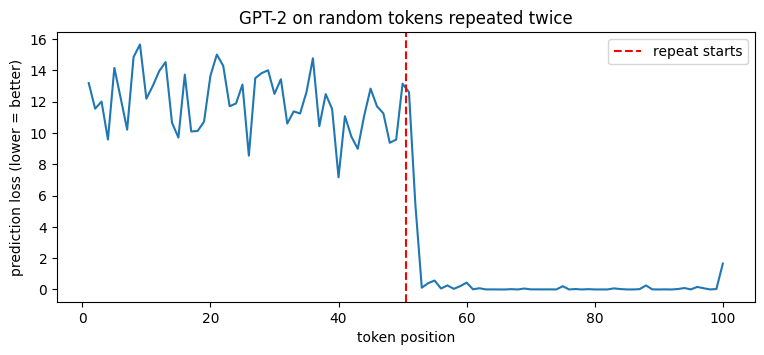

Average loss, first copy : 11.98
Average loss, second copy: 0.21


In [ ]:
set_seed(0)
N = 50
rand = torch.randint(1000, 20000, (N,))
seq = torch.cat([torch.tensor([tok_g.eos_token_id]), rand, rand]).unsqueeze(0).to(device)

with torch.no_grad():
    out = model_g(seq, output_attentions=True)
loss = F.cross_entropy(out.logits[0, :-1].float(), seq[0, 1:], reduction="none").cpu()

plt.figure(figsize=(9, 3.5))
plt.plot(range(1, 2 * N + 1), loss.numpy())
plt.axvline(N + 0.5, c="red", ls="--", label="repeat starts")
plt.xlabel("token position"); plt.ylabel("prediction loss (lower = better)")
plt.title("GPT-2 on random tokens repeated twice"); plt.legend(); plt.show()
print(f"Average loss, first copy : {loss[:N].mean():.2f}")
print(f"Average loss, second copy: {loss[N + 1:].mean():.2f}")

Which attention heads do this? For each head we measure an **induction score**: how much attention a token in the second copy pays to the token *right after* its earlier occurrence.

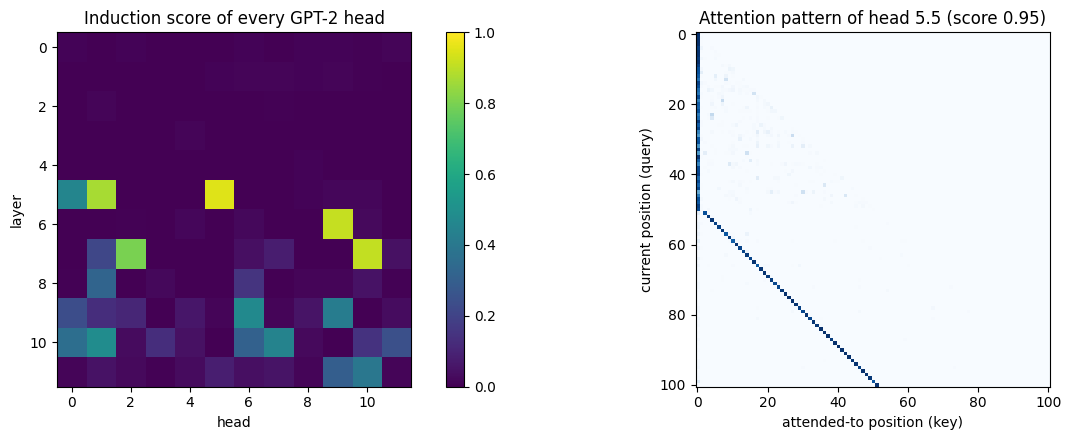

In [ ]:
att = torch.stack(out.attentions)[:, 0].float().cpu()      # (layers, heads, query, key)
js = torch.arange(N + 1, 2 * N + 1)                         # positions in the second copy
ind_score = att[:, :, js, js - N + 1].mean(-1)              # (layers, heads)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
im = axes[0].imshow(ind_score, cmap="viridis", vmin=0, vmax=1)
axes[0].set_xlabel("head"); axes[0].set_ylabel("layer"); axes[0].set_title("Induction score of every GPT-2 head")
plt.colorbar(im, ax=axes[0])

L, H = divmod(int(ind_score.argmax()), ind_score.shape[1])
axes[1].imshow(att[L, H], cmap="Blues")
axes[1].set_title(f"Attention pattern of head {L}.{H} (score {ind_score[L, H]:.2f})")
axes[1].set_xlabel("attended-to position (key)"); axes[1].set_ylabel("current position (query)")
plt.tight_layout(); plt.show()

> 💡 **Point out:**
> - Loss is high on the first copy (random tokens are unpredictable) and drops sharply on the second copy: the model is copying from context.
> - Only a few heads, in the middle layers, have high induction scores. In the attention pattern of the strongest head, the off-diagonal stripe shows each token in the second half looking back at "what came after me last time".
> - This is not the *whole* explanation of in-context learning, but it's a concrete, visible piece of the mechanism.

In [ ]:
del model_g, model_q, out, att; clear_gpu()

---
# Part 2: Instruction Fine-Tuning

A base model continues text. Ask it a question and it may continue with *more questions*, because that's what often follows a question on the web. **Instruction fine-tuning** trains the model on many (instruction, response) pairs so that it learns the behaviour "when given an instruction, respond to it, then stop".

## 2.1 Base model vs instruction-tuned model
**Qwen2.5-0.5B** and **Qwen2.5-0.5B-Instruct** have the same architecture and size. The only difference is extra training on instructions (plus preference tuning). We give both the same requests.

In [ ]:
tok_b, model_b = load("Qwen/Qwen2.5-0.5B")
tok_i, model_i = load("Qwen/Qwen2.5-0.5B-Instruct")

REQUESTS = [
    "Give me three tips for staying focused while studying.",
    "Translate into French: Where is the train station?",
    "Write a haiku about the monsoon.",
    "Is 17 a prime number? Answer yes or no, then explain briefly.",
]

for r in REQUESTS:
    base_out, base_stop = generate(model_b, tok_b, r, max_new_tokens=100, repetition_penalty=1.1)
    chat = tok_i.apply_chat_template([{"role": "user", "content": r}], tokenize=False, add_generation_prompt=True)
    inst_out, inst_stop = generate(model_i, tok_i, chat, max_new_tokens=100, repetition_penalty=1.1)
    print("REQUEST:", r)
    print(f"\n[BASE]      (stopped on its own: {base_stop})\n{base_out}")
    print(f"\n[INSTRUCT]  (stopped on its own: {inst_stop})\n{inst_out}")
    print("=" * 100)

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

REQUEST: Give me three tips for staying focused while studying.

[BASE]      (stopped on its own: False)
1. Set clear goals: Before starting your study, it's essential to set specific and achievable goals that align with your learning objectives. This will help you stay motivated and focused throughout the process.

2. Create a conducive environment: Make sure your study space is well-lit, quiet, and free from distractions. Use tools like noise-cancelling headphones or earplugs if necessary to reduce background noise.

3. Take regular breaks: Taking short breaks during study sessions can help prevent burnout

[INSTRUCT]  (stopped on its own: False)
Certainly! Here are three tips to help you stay focused while studying:

1. **Set Clear Goals**: Before starting your study session, make sure you have a clear understanding of what you want to achieve. Break down your goals into smaller, manageable tasks that can be completed in one sitting.

2. **Create a Study Environment**: Find a quiet 

> 💡 **Point out:** look at *behaviour*, not just correctness. The base model often drifts into continuing the text (new questions, lists, web-page-like text) and rarely stops on its own. The instruction-tuned model answers the request and stops. Modern base models have seen many Q&A pages on the web, so they sometimes answer too, but much less reliably.

## 2.2 What the instruct model actually sees: the chat template
Instruction-tuned models are trained with a fixed format. Special tokens mark who is speaking and where each turn ends. The model learns to produce `<|im_end|>` when its answer is finished, which is why it stops.

In [ ]:
print(tok_i.apply_chat_template([{"role": "user", "content": "Write a haiku about the monsoon."}],
                                tokenize=False, add_generation_prompt=True))

<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>
<|im_start|>user
Write a haiku about the monsoon.<|im_end|>
<|im_start|>assistant



In [ ]:
del model_b, model_i; clear_gpu()

## 2.3 What instruction-tuning data looks like
We use **Dolly-15k**: about 15,000 instruction–response pairs written by Databricks employees, in categories like open QA, brainstorming, summarisation and classification.

In [ ]:
dolly = load_dataset("databricks/databricks-dolly-15k", split="train")
print(pd.Series(dolly["category"]).value_counts().to_string(), "\n")
for ex in dolly.shuffle(seed=1).select(range(3)):
    print(f"[{ex['category']}]")
    print("INSTRUCTION:", ex["instruction"])
    if ex["context"]:
        print("CONTEXT    :", ex["context"][:200], "...")
    print("RESPONSE   :", ex["response"][:300])
    print("-" * 100)

README.md:   0%|          | 0.00/8.20k [00:00<?, ?B/s]

databricks-dolly-15k.jsonl: reconstructing file:   0%|          |  0.00B / 13.1MB            

databricks-dolly-15k.jsonl: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/15011 [00:00<?, ? examples/s]

open_qa                   3742
general_qa                2191
classification            2136
closed_qa                 1773
brainstorming             1766
information_extraction    1506
summarization             1188
creative_writing           709 

[summarization]
INSTRUCTION: Write some important points about the National Basketball League from the given text
CONTEXT    : The National Basketball League (NBL) was a professional basketball league in the United States established in 1937. After the 1948–49 season, its twelfth, it merged with the Basketball Association of  ...
RESPONSE   : 1. In the United States, a professional basketball league called the National Basketball League (NBL) was founded in 1937.
2. It united with the Basketball Association of America (BAA) to become the National Basketball Association after its twelfth season, 1948–1949 (NBA).
3. The Atlanta Hawks, Detr
----------------------------------------------------------------------------------------------------
[ge

## 2.4 How the training works: loss only on the response
Each example is turned into one piece of text with a template. The model is trained with ordinary next-token prediction, **but the loss is only computed on the response tokens**. The instruction is context to read, not text to learn to write. In code, ignored positions get the label `-100`.

Below, **grey** tokens are ignored by the loss and **green** tokens are trained on. Note the end-of-text token at the end, which teaches the model to stop.

In [ ]:
tok_gpt = AutoTokenizer.from_pretrained("openai-community/gpt2")
tok_gpt.pad_token = tok_gpt.eos_token
MAX_LEN = 256


def format_prompt(instruction, context=""):
    if context and context.strip():
        return f"### Instruction:\n{instruction}\n\n### Input:\n{context}\n\n### Response:\n"
    return f"### Instruction:\n{instruction}\n\n### Response:\n"


def tokenize_example(ex):
    p = tok_gpt(format_prompt(ex["instruction"], ex["context"]), add_special_tokens=False).input_ids
    r = tok_gpt(ex["response"], add_special_tokens=False).input_ids + [tok_gpt.eos_token_id]
    ids = (p + r)[:MAX_LEN]
    labels = ([-100] * len(p) + r)[:MAX_LEN]
    return {"input_ids": ids, "attention_mask": [1] * len(ids), "labels": labels}


def show_masking(ex):
    t = tokenize_example(ex)
    spans = []
    for tid, lab in zip(t["input_ids"], t["labels"]):
        s = escape(tok_gpt.decode([tid])).replace("\n", "↵<br>")
        bg = "rgba(150,150,150,0.30)" if lab == -100 else "rgba(40,180,90,0.40)"
        spans.append(f'<span style="background:{bg};border-radius:3px;margin:0 1px;padding:1px 0">{s}</span>')
    legend = ('<p><span style="background:rgba(150,150,150,0.30);padding:2px 6px">ignored (label = -100)</span> '
              '<span style="background:rgba(40,180,90,0.40);padding:2px 6px">trained on</span></p>')
    display(HTML(legend + '<div style="font-family:monospace;line-height:1.9">' + "".join(spans) + "</div>"))


short = dolly.filter(lambda ex: len(ex["response"]) < 200 and not ex["context"])
show_masking(short[3])

Filter:   0%|          | 0/15011 [00:00<?, ? examples/s]

## 2.5 Live: instruction fine-tune GPT-2 in about two minutes
We take plain **GPT-2** and fine-tune it on 2,000 short Dolly examples. Then we compare its answers before and after on instructions it has never seen. *(Training takes about 2–3 minutes on a T4.)*

Filter:   0%|          | 0/15011 [00:00<?, ? examples/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1050 > 1024). Running this sequence through the model will result in indexing errors


Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Step,Training Loss
10,3.160380
20,2.920882
30,2.838218
40,2.897264
50,2.886718
60,2.672839
70,2.786750
80,2.813619
90,2.821944
100,2.866241


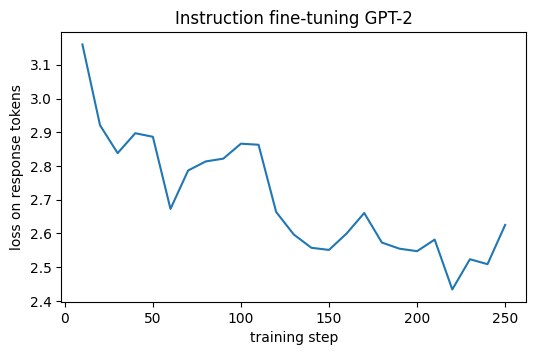

In [ ]:
fits = dolly.filter(lambda ex: len(tokenize_example(ex)["input_ids"]) < MAX_LEN)
train_raw = fits.shuffle(seed=42).select(range(2000))
train_ds = train_raw.map(tokenize_example, remove_columns=train_raw.column_names)

set_seed(42)
model_ft = AutoModelForCausalLM.from_pretrained("openai-community/gpt2").to(device)
model_ft.config.pad_token_id = tok_gpt.eos_token_id
args = TrainingArguments(output_dir="./gpt2-ift-demo", per_device_train_batch_size=16, num_train_epochs=2,
                         learning_rate=5e-5, warmup_steps=10, lr_scheduler_type="cosine", logging_steps=10,
                         save_strategy="no", fp16=(device == "cuda"), report_to="none", seed=42)
trainer = Trainer(model=model_ft, args=args, train_dataset=train_ds,
                  data_collator=DataCollatorForSeq2Seq(tok_gpt, padding=True, label_pad_token_id=-100))
trainer.train()
model_ft.eval()

logs = [l for l in trainer.state.log_history if "loss" in l]
plt.figure(figsize=(6, 3.5))
plt.plot([l["step"] for l in logs], [l["loss"] for l in logs])
plt.xlabel("training step"); plt.ylabel("loss on response tokens"); plt.title("Instruction fine-tuning GPT-2")
plt.show()

In [ ]:
base_gpt2 = AutoModelForCausalLM.from_pretrained("openai-community/gpt2").to(device).eval()

NEW_INSTRUCTIONS = [
    ("Give three tips for staying healthy.", ""),
    ("What is the difference between a cat and a dog?", ""),
    ("Write a short message to my manager asking for Friday off.", ""),
    ("Summarize the text below in one sentence.",
     "The city council met on Tuesday to discuss the new public library. After a long debate, members "
     "voted 7 to 2 to approve funding, and construction is expected to begin next spring."),
]


def answer(model, instruction, context=""):
    text, stopped = generate(model, tok_gpt, format_prompt(instruction, context), max_new_tokens=100,
                             repetition_penalty=1.2, no_repeat_ngram_size=3, eos_token_id=tok_gpt.eos_token_id)
    return text.split("###")[0].strip(), stopped


for instr, ctx in NEW_INSTRUCTIONS:
    b, bs = answer(base_gpt2, instr, ctx)
    f_, fs = answer(model_ft, instr, ctx)
    print("INSTRUCTION:", instr)
    print(f"\n[GPT-2 BEFORE]  (stopped on its own: {bs})\n{b}")
    print(f"\n[GPT-2 AFTER]   (stopped on its own: {fs})\n{f_}")
    print("=" * 100)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

INSTRUCTION: Give three tips for staying healthy.

[GPT-2 BEFORE]  (stopped on its own: False)
, "I'm not sure how to respond," said Drs., who are also the lead author of a new book on nutrition and health that is available from The American Heart Association's website . She added that she was surprised by what happened when her husband died in 2010 after being diagnosed with heart disease at age 45. Her response? To help him get back into shape again as he worked toward his goal — which would be an eight-week weight loss program based around eating less fat (and more

[GPT-2 AFTER]   (stopped on its own: True)
1) Avoid eating too much food and drink alcohol, especially if you are a heavy smoker or have diabetes mellitus (DM). 2), Drink plenty of water to keep your blood sugar levels low while exercising regularly. 3 – Exercise frequently in the morning so that it is easier to get up early on day one
INSTRUCTION: What is the difference between a cat and a dog?

[GPT-2 BEFORE]  (stopped

> 💡 **Point out:**
> - **Before**, GPT-2 treats the prompt as a document to continue: it rambles, repeats the template or drifts off-topic, and doesn't stop.
> - **After** only 2,000 examples and a couple of minutes, it answers in the right *shape* and stops on its own.
> - But the answers are often still shallow or wrong. A 124M model doesn't know much, and instruction tuning mostly teaches **how to respond**, not new knowledge. The LIMA paper (Zhou et al., 2023) calls this the *Superficial Alignment Hypothesis*.

### Unlike ICL, the weights really changed
In 1.5 the weights of the prompted model were identical before and after. Here we measure how much each layer of GPT-2 moved during fine-tuning.

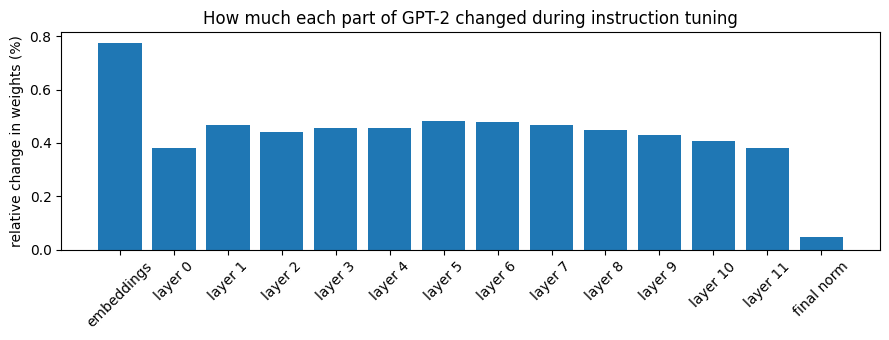

Fingerprint before: -62119.8825   after: -61594.4495


In [ ]:
base_params = dict(base_gpt2.named_parameters())
groups = {}
for n, p in model_ft.named_parameters():
    key = "embeddings" if ("wte" in n or "wpe" in n) else ("layer " + n.split(".")[2] if ".h." in n else "final norm")
    d = (p.detach().float() - base_params[n].detach().float()).norm().item() ** 2
    b = base_params[n].detach().float().norm().item() ** 2
    groups.setdefault(key, [0.0, 0.0]); groups[key][0] += d; groups[key][1] += b

order = ["embeddings"] + [f"layer {i}" for i in range(12)] + ["final norm"]
rel = [100 * np.sqrt(groups[k][0] / groups[k][1]) for k in order]
plt.figure(figsize=(9, 3.5))
plt.bar(order, rel); plt.xticks(rotation=45)
plt.ylabel("relative change in weights (%)"); plt.title("How much each part of GPT-2 changed during instruction tuning")
plt.tight_layout(); plt.show()
print(f"Fingerprint before: {fingerprint(base_gpt2):.4f}   after: {fingerprint(model_ft):.4f}")

> 💡 **Point out:** the changes are small (a few percent at most) but spread across **every** layer. A small, broad nudge to the weights is enough to change the model's behaviour from "continue text" to "follow instructions", and unlike ICL, this change is permanent.